In [5]:
print("Let's Start Niyatiiiii")

Let's Start Niyatiiiii


In [4]:
import micropip 
micropip.install("scikit-learn")

<coroutine object PackageManager.install at 0x15cefd8>

In [5]:
import sklearn
print(sklearn.__version__)

1.8.0


In [1]:
import numpy as np
import sklearn

print("NumPy version:", np.__version__)
print("Scikit-learn version:", sklearn.__version__)

NumPy version: 2.4.6
Scikit-learn version: 1.8.0


In [6]:
# Importing libraries and setting the data folders

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.linear_model import LinearRegression, HuberRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

DATA_DIR = Path(r"E:\AIML") 
print("CSV folder:", DATA_DIR.resolve())

CSV folder: /drive/notebooks/E:\AIML


In [2]:
from pathlib import Path

DATA_DIR = Path.cwd()

print("Current folder:", DATA_DIR)
print("CSV files:", list(DATA_DIR.glob("*.csv")))

Current folder: /drive/notebooks
CSV files: [PosixPath('/drive/notebooks/A_winding_resistance.csv.csv'), PosixPath('/drive/notebooks/A_winding_resistance_logger.csv.csv'), PosixPath('/drive/notebooks/B_pv_plant.csv.csv'), PosixPath('/drive/notebooks/C_feeder_load.csv.csv'), PosixPath('/drive/notebooks/D_motor_thermal.csv.csv'), PosixPath('/drive/notebooks/E_bearing_condition.csv.csv'), PosixPath('/drive/notebooks/F_pq_events.csv.csv')]


In [7]:
# Loading all six datasets into DataFrames
# Each variable remains available for use in later Part A–F cells

import pandas as pd
A_df = pd.read_csv(DATA_DIR / "A_winding_resistance.csv")
A_logger_df = pd.read_csv(DATA_DIR / "A_winding_resistance_logger.csv")
B_df = pd.read_csv(DATA_DIR / "B_pv_plant.csv")
C_df = pd.read_csv(DATA_DIR / "C_feeder_load.csv")
D_df = pd.read_csv(DATA_DIR / "D_motor_thermal.csv")
E_df = pd.read_csv(DATA_DIR / "E_bearing_condition.csv")
F_df = pd.read_csv(DATA_DIR / "F_pq_events.csv")

print("All seven CSV files loaded successfully.")

All seven CSV files loaded successfully.


In [8]:
# Previewing every dataFrame and checking its size/columns

dataframes = {
    "A_df — winding resistance": A_df,
    "A_logger_df — logger winding resistance": A_logger_df,
    "B_df — PV plant": B_df,
    "C_df — feeder load": C_df,
    "D_df — motor thermal": D_df,
    "E_df — bearing condition": E_df,
    "F_df — power-quality events": F_df,
}

for name, df in dataframes.items():
    print("\\n" + "=" * 70)
    print(name, "| shape:", df.shape)
    print("Columns:", df.columns.tolist())
    display(df.head())

\n======================================================================
A_df — winding resistance | shape: (25, 2)
Columns: ['temp_C', 'resistance_ohm']


,temp_C,resistance_ohm
0,17.5,0.8424
1,19.4,0.8487
2,33.0,0.8954
3,35.0,0.9023
4,38.5,0.9128


\n======================================================================
A_logger_df — logger winding resistance | shape: (28, 2)
Columns: ['temp_C', 'resistance_ohm']


,temp_C,resistance_ohm
0,17.5,0.8424
1,19.4,0.8487
2,33.0,0.8954
3,35.0,0.9023
4,35.0,1.0223


\n======================================================================
B_df — PV plant | shape: (500, 3)
Columns: ['irradiance_Wm2', 'module_temp_C', 'ac_power_kW']


...

,i_band_01,i_band_02,i_band_03,i_band_04,i_band_05,i_band_06,i_band_07,i_band_08,i_band_09,i_band_10,...,ambient_C,coolant_temp_C,coolant_flow_lpm,aux_01,aux_02,aux_03,aux_04,aux_05,winding_rise_K,split
0,0.9079,1.1186,0.7758,1.0109,0.7772,0.7727,0.6787,0.6522,0.8408,0.9805,...,28.47,27.21,15.61,0.5189,0.7287,-0.4787,1.0270,-1.3921,30.73,train
1,0.7195,1.1556,0.7932,0.6915,0.6068,0.9060,1.0885,1.1185,1.0739,1.0018,...,27.21,32.09,9.23,0.3453,1.3473,-0.1483,-0.5227,1.6997,37.71,train
2,1.1740,1.3324,1.3320,1.4269,1.4697,1.4762,1.6861,1.3388,1.0914,1.0476,...,34.24,32.05,17.50,-0.9668,-0.1806,-1.9154,0.5241,1.3685,50.31,train
3,0.9635,0.8532,0.8777,0.9964,0.6365,0.4864,0.6439,0.5781,0.5834,0.3656,...,26.44,20.73,11.33,0.2485,0.8471,-0.0166,-1.0950,-0.5086,35.84,train
4,1.0220,1.0706,1.0601,1.1306,1.2061,1.2360,1.3131,1.1780,1.2184,1.0229,...,27.32,26.90,12.81,0.9548,0.3593,0.9370,0.2067,-0.6532,47.99,train


\n======================================================================
E_df — bearing condition | shape: (600, 4)
Columns: ['vib_rms_mm_s', 'kurtosis', 'fault', 'split']


,vib_rms_mm_s,kurtosis,fault,split
0,1.851,2.677,0,train
1,2.062,2.746,0,train
2,1.518,3.031,0,train
3,1.597,3.281,0,train
4,2.853,2.789,0,train


\n======================================================================
F_df — power-quality events | shape: (700, 4)
Columns: ['rms_pu', 'thd_pct', 'event', 'split']


,rms_pu,thd_pct,event,split
0,0.6754,2.54,sag,train
1,0.9770,6.24,harmonic,train
2,0.8352,3.17,sag,train
3,0.9827,5.79,harmonic,train
4,0.7181,2.93,sag,train


In [9]:
# Checking data types, missing values and summary statistics

for name, df in dataframes.items():
    print("\\n" + "=" * 70)
    print(name)
    print("Data types:")
    display(df.dtypes.to_frame("data_type"))
    print("Missing values per column:")
    display(df.isna().sum().to_frame("missing_count"))
    print("Summary statistics:")
    display(df.describe(include="all").T)

\n======================================================================
A_df — winding resistance
Data types:


,data_type
temp_C,float64
resistance_ohm,float64


Missing values per column:


,missing_count
temp_C,0
resistance_ohm,0


Summary statistics:


...

,data_type
rms_pu,float64
thd_pct,float64
event,str
split,str


Missing values per column:


,missing_count
rms_pu,0
thd_pct,0
event,0
split,0


Summary statistics:


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
rms_pu,700.0,NaN,NaN,NaN,0.973312,0.116363,0.5975,0.9621,0.9947,1.0182,1.2033
thd_pct,700.0,NaN,NaN,NaN,3.747314,2.46136,0.3,2.0675,3.015,4.3775,12.26
event,700,4,normal,300,NaN,NaN,NaN,NaN,NaN,NaN,NaN
split,700,2,train,490,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [10]:
# (1) — Inspect (Part A) and define the input X and target y niyatiiiii
display(A_df.head())
print("Shape:", A_df.shape)
print("Columns:", A_df.columns.tolist())

required = {"temp_C", "resistance_ohm"}
missing = required - set(A_df.columns)
if missing:
    raise ValueError(f"Missing expected columns in A_df: {missing}")

X_A = A_df[["temp_C"]]           # 2D input required by scikit-learn
y_A = A_df["resistance_ohm"]     # 1D target

print("X_A shape:", X_A.shape)
print("y_A shape:", y_A.shape)

,temp_C,resistance_ohm
0,17.5,0.8424
1,19.4,0.8487
2,33.0,0.8954
3,35.0,0.9023
4,38.5,0.9128


Shape: (25, 2)
Columns: ['temp_C', 'resistance_ohm']
X_A shape: (25, 1)
y_A shape: (25,)


In [13]:
# (2) — Calculate slope or intercept directly with Numpy niyatiiii
import numpy as np
T = A_df["temp_C"].to_numpy(dtype=float)
R = A_df["resistance_ohm"].to_numpy(dtype=float)

T_mean, R_mean = T.mean(), R.mean()
slope_formula = np.sum((T - T_mean) * (R - R_mean)) / np.sum((T - T_mean) ** 2)
intercept_formula = R_mean - slope_formula * T_mean
R_pred_formula = intercept_formula + slope_formula * T

from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

print(f"Intercept: {intercept_formula:.8f} ohm")
print(f"Slope:     {slope_formula:.8f} ohm/°C")
print(f"RMSE:      {np.sqrt(mean_squared_error(R, R_pred_formula)):.8f} ohm")
print(f"MAE:       {mean_absolute_error(R, R_pred_formula):.8f} ohm")
print(f"R²:        {r2_score(R, R_pred_formula):.6f}")

Intercept: 0.78390522 ohm
Slope:     0.00333176 ohm/°C
RMSE:      0.00176288 ohm
MAE:       0.00149021 ohm
R²:        0.999430


In [16]:
# (3) — Fitting ordinary least square regression :)

from sklearn.linear_model import LinearRegression, HuberRegressor
linear_model_A = LinearRegression()
linear_model_A.fit(X_A, y_A)
R_pred_linear = linear_model_A.predict(X_A)

print(f"Intercept: {linear_model_A.intercept_:.8f} ohm")
print(f"Slope:     {linear_model_A.coef_[0]:.8f} ohm/°C")
print(f"RMSE:      {np.sqrt(mean_squared_error(y_A, R_pred_linear)):.8f} ohm")
print(f"MAE:       {mean_absolute_error(y_A, R_pred_linear):.8f} ohm")
print(f"R²:        {r2_score(y_A, R_pred_linear):.6f}")
print("Slope difference from formula:", abs(slope_formula - linear_model_A.coef_[0]))
print("Intercept difference from formula:", abs(intercept_formula - linear_model_A.intercept_))

Intercept: 0.78390522 ohm
Slope:     0.00333176 ohm/°C
RMSE:      0.00176288 ohm
MAE:       0.00149021 ohm
R²:        0.999430
Slope difference from formula: 8.673617379884035e-19
Intercept difference from formula: 1.1102230246251565e-16


In [17]:
# (4) — Fitting HuberRegressor and comparing model metrics :)

from sklearn.linear_model import LinearRegression, HuberRegressor
huber_model_A = HuberRegressor()
huber_model_A.fit(X_A, y_A)
R_pred_huber = huber_model_A.predict(X_A)

print(f"Huber intercept: {huber_model_A.intercept_:.8f} ohm")
print(f"Huber slope:     {huber_model_A.coef_[0]:.8f} ohm/°C")
print(f"Huber RMSE:      {np.sqrt(mean_squared_error(y_A, R_pred_huber)):.8f} ohm")
print(f"Huber MAE:       {mean_absolute_error(y_A, R_pred_huber):.8f} ohm")
print(f"Huber R²:        {r2_score(y_A, R_pred_huber):.6f}")

comparison_A = pd.DataFrame({
    "model": ["Formula least squares", "LinearRegression", "HuberRegressor"],
    "intercept_ohm": [intercept_formula, linear_model_A.intercept_, huber_model_A.intercept_],
    "slope_ohm_per_C": [slope_formula, linear_model_A.coef_[0], huber_model_A.coef_[0]],
    "RMSE_ohm": [
        np.sqrt(mean_squared_error(y_A, R_pred_formula)),
        np.sqrt(mean_squared_error(y_A, R_pred_linear)),
        np.sqrt(mean_squared_error(y_A, R_pred_huber)),
    ],
    "MAE_ohm": [
        mean_absolute_error(y_A, R_pred_formula),
        mean_absolute_error(y_A, R_pred_linear),
        mean_absolute_error(y_A, R_pred_huber),
    ],
})
display(comparison_A)

Huber intercept: 0.78402519 ohm
Huber slope:     0.00333001 ohm/°C
Huber RMSE:      0.00176340 ohm
Huber MAE:       0.00147702 ohm
Huber R²:        0.999430


,model,intercept_ohm,slope_ohm_per_C,RMSE_ohm,MAE_ohm
0,Formula least squares,0.783905,0.003332,0.001763,0.001490
1,LinearRegression,0.783905,0.003332,0.001763,0.001490
2,HuberRegressor,0.784025,0.003330,0.001763,0.001477


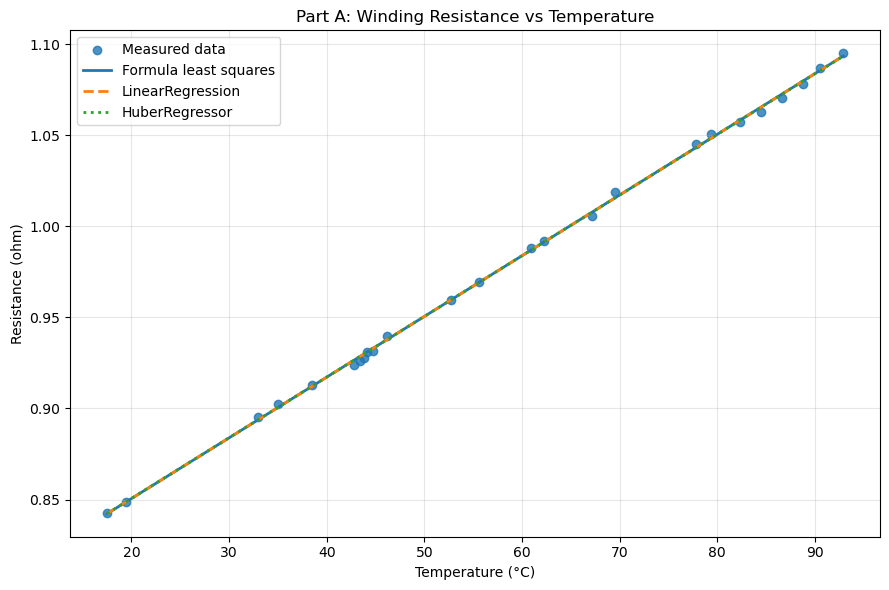

In [18]:
# (5) — Plotting measured data and all fitted lines

import matplotlib.pyplot as plt
temperature_grid = np.linspace(A_df["temp_C"].min(), A_df["temp_C"].max(), 200)
grid_df = pd.DataFrame({"temp_C": temperature_grid})

plt.figure(figsize=(9, 6))
plt.scatter(A_df["temp_C"], A_df["resistance_ohm"], label="Measured data", alpha=0.8)
plt.plot(temperature_grid, intercept_formula + slope_formula * temperature_grid,
         label="Formula least squares", linewidth=2)
plt.plot(temperature_grid, linear_model_A.predict(grid_df),
         "--", label="LinearRegression", linewidth=2)
plt.plot(temperature_grid, huber_model_A.predict(grid_df),
         ":", label="HuberRegressor", linewidth=2)
plt.xlabel("Temperature (°C)")
plt.ylabel("Resistance (ohm)")
plt.title("Part A: Winding Resistance vs Temperature")
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

In [19]:
# (6) Calculating residuals and flag |residual| > 0.02 ohm

A_results = A_df.copy()
A_results["predicted_resistance_ohm"] = R_pred_linear
A_results["residual_ohm"] = A_results["resistance_ohm"] - A_results["predicted_resistance_ohm"]
A_results["absolute_residual_ohm"] = A_results["residual_ohm"].abs()
A_results["flag_abs_residual_gt_0_02"] = A_results["absolute_residual_ohm"] > 0.02

print("Number of rows with |residual| > 0.02 ohm:",
      int(A_results["flag_abs_residual_gt_0_02"].sum()))
display(A_results.loc[A_results["flag_abs_residual_gt_0_02"]]
        .sort_values("absolute_residual_ohm", ascending=False))
display(A_results.sort_values("absolute_residual_ohm", ascending=False))

Number of rows with |residual| > 0.02 ohm: 0


,temp_C,resistance_ohm,predicted_resistance_ohm,residual_ohm,absolute_residual_ohm,flag_abs_residual_gt_0_02


,temp_C,resistance_ohm,predicted_resistance_ohm,residual_ohm,absolute_residual_ohm,flag_abs_residual_gt_0_02
16,69.5,1.0190,1.015462,0.003538,0.003538,False
5,42.8,0.9237,0.926505,-0.002805,0.002805,False
20,84.5,1.0627,1.065439,-0.002739,0.002739,False
6,43.4,0.9260,0.928504,-0.002504,0.002504,False
18,79.4,1.0507,1.048447,0.002253,0.002253,False
21,86.6,1.0702,1.072436,-0.002236,0.002236,False
15,67.2,1.0056,1.007799,-0.002199,0.002199,False
17,77.8,1.0453,1.043116,0.002184,0.002184,False
7,43.8,0.9279,0.929836,-0.001936,0.001936,False
3,35.0,0.9023,0.900517,0.001783,0.001783,False


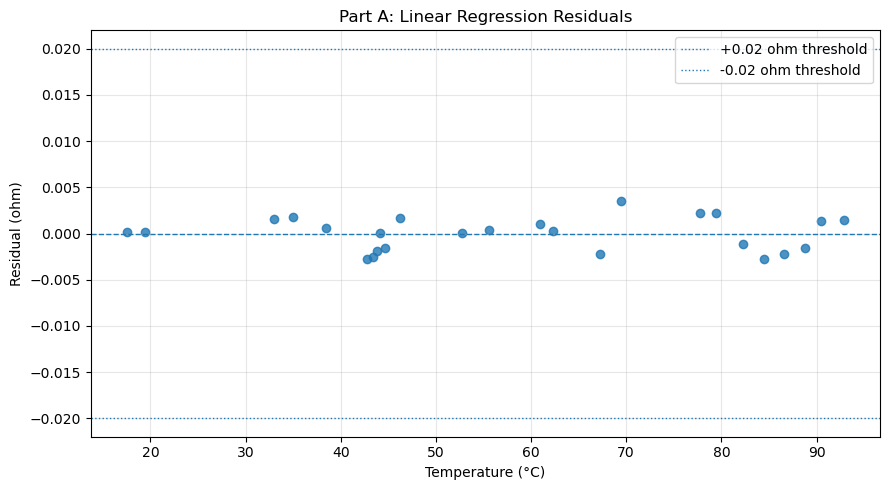

In [20]:
# (7) Residual plot

import matplotlib.pyplot as plt
plt.figure(figsize=(9, 5))
plt.scatter(A_results["temp_C"], A_results["residual_ohm"], alpha=0.8)
plt.axhline(0, linestyle="--", linewidth=1)
plt.axhline(0.02, linestyle=":", linewidth=1, label="+0.02 ohm threshold")
plt.axhline(-0.02, linestyle=":", linewidth=1, label="-0.02 ohm threshold")
plt.xlabel("Temperature (°C)")
plt.ylabel("Residual (ohm)")
plt.title("Part A: Linear Regression Residuals")
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

,temp_C,resistance_ohm
0,17.5,0.8424
1,19.4,0.8487
2,33.0,0.8954
3,35.0,0.9023
4,35.0,1.0223


,temp_C,resistance_ohm
count,28.000000,28.000000
mean,57.746429,0.951093
std,22.008289,0.202168
min,17.500000,0.000000
25%,43.250000,0.925425
50%,54.150000,0.978650
75%,78.200000,1.052275
max,92.900000,1.148300


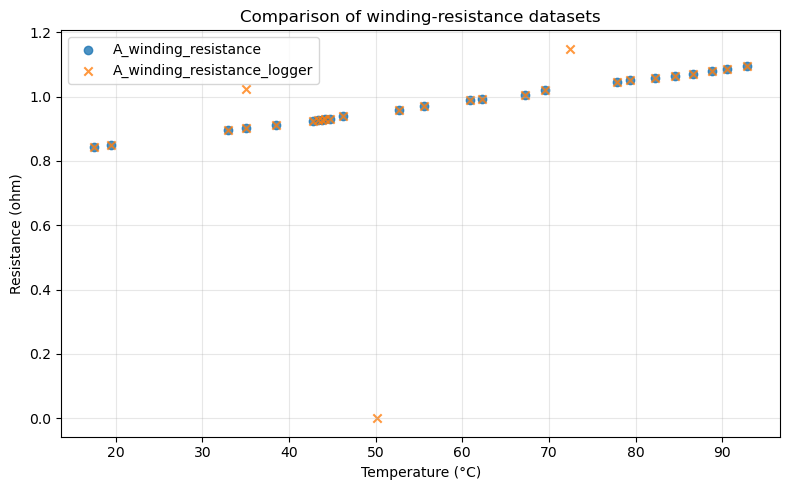

In [21]:
# (8) Previewing and comparing those two part A datasets :(

display(A_logger_df.head())
display(A_logger_df.describe())

if {"temp_C", "resistance_ohm"}.issubset(A_logger_df.columns):
    plt.figure(figsize=(8, 5))
    plt.scatter(A_df["temp_C"], A_df["resistance_ohm"],
                label="A_winding_resistance", alpha=0.8)
    plt.scatter(A_logger_df["temp_C"], A_logger_df["resistance_ohm"],
                label="A_winding_resistance_logger", alpha=0.8, marker="x")
    plt.xlabel("Temperature (°C)")
    plt.ylabel("Resistance (ohm)")
    plt.title("Comparison of winding-resistance datasets")
    plt.grid(True, alpha=0.3)
    plt.legend()
    plt.tight_layout()
    plt.show()
else:
    print("Expected temp_C and resistance_ohm columns were not found in A_logger_df.")